In [9]:
# Homework 3
# Gabriel Almodovar
# Student ID: 801296062

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
# FUNCTIONS USED THROUGHOUT THE HOMEWORK

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def binary_loss(Y, probabilities):
    probabilities = np.clip(probabilities, 1e-12, 1 - 1e-12)

    return -np.mean(
        Y * np.log(probabilities)
        + (1 - Y) * np.log(1 - probabilities)
    )


def gradient_descent(X_train, Y_train, X_test, Y_test,
                     learning_rate, max_iterations, penalty=0):

    m = len(Y_train)

    X_train_b = np.c_[np.ones(len(X_train)), X_train]
    X_test_b = np.c_[np.ones(len(X_test)), X_test]

    theta = np.zeros(X_train_b.shape[1])

    train_loss = []
    test_loss = []
    train_accuracy = []
    test_accuracy = []

    for iteration in range(max_iterations):

        probabilities = sigmoid(X_train_b.dot(theta))
        errors = probabilities - Y_train

        gradients = X_train_b.T.dot(errors) / m

        # Apply the L2 penalty to weights, but not the intercept.
        gradients[1:] += (penalty / m) * theta[1:]

        theta -= learning_rate * gradients

        train_probabilities = sigmoid(X_train_b.dot(theta))
        test_probabilities = sigmoid(X_test_b.dot(theta))

        train_loss.append(
            binary_loss(Y_train, train_probabilities)
        )
        test_loss.append(
            binary_loss(Y_test, test_probabilities)
        )

        train_accuracy.append(
            np.mean((train_probabilities >= 0.5) == Y_train)
        )
        test_accuracy.append(
            np.mean((test_probabilities >= 0.5) == Y_test)
        )

    return theta, train_loss, test_loss, train_accuracy, test_accuracy


def evaluate_model(theta, X_test, Y_test):

    X_test_b = np.c_[np.ones(len(X_test)), X_test]

    probabilities = sigmoid(X_test_b.dot(theta))
    predictions = (probabilities >= 0.5).astype(int)

    results = {
        'Accuracy': accuracy_score(Y_test, predictions),
        'Precision': precision_score(
            Y_test, predictions, zero_division=0
        ),
        'Recall': recall_score(
            Y_test, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            Y_test, predictions, zero_division=0
        )
    }

    matrix = confusion_matrix(
        Y_test, predictions, labels=[0, 1]
    )

    return results, matrix

In [11]:
# PROBLEM 1: LOAD THE DIABETES DATASET

file_path = '/content/drive/My Drive/Courses/Intro-to-ML/Datasets/diabetes.csv'

Diabetes = pd.DataFrame(pd.read_csv(file_path))
Diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [12]:
# CHECK THE DATA

print(Diabetes.isnull().sum() * 100 / Diabetes.shape[0])

zero_missing = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print((Diabetes[zero_missing] == 0).sum())


# 80/20 TRAINING AND TEST SPLIT

X_diabetes = Diabetes.drop(columns='Outcome').copy()
Y_diabetes = Diabetes['Outcome'].to_numpy(dtype=int)

# These measurements cannot meaningfully be zero.
X_diabetes[zero_missing] = X_diabetes[zero_missing].replace(
    0, np.nan
)

X_train_df, X_test_df, Y_train_1, Y_test_1 = train_test_split(
    X_diabetes,
    Y_diabetes,
    test_size=0.20,
    random_state=42,
    stratify=Y_diabetes
)

# Fit preprocessing on training data only.
imputer_1 = SimpleImputer(strategy='median')

X_train_imputed = imputer_1.fit_transform(X_train_df)
X_test_imputed = imputer_1.transform(X_test_df)

scaler_1 = StandardScaler()

X_train_1 = scaler_1.fit_transform(X_train_imputed)
X_test_1 = scaler_1.transform(X_test_imputed)

print("Training samples:", len(Y_train_1))
print("Test samples:", len(Y_test_1))

Pregnancies                 0.0
Glucose                     0.0
BloodPressure               0.0
SkinThickness               0.0
Insulin                     0.0
BMI                         0.0
DiabetesPedigreeFunction    0.0
Age                         0.0
Outcome                     0.0
dtype: float64
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Training samples: 614
Test samples: 154


In [13]:
# PROBLEM 1: LOGISTIC REGRESSION

learning_rate_1 = 0.1
max_iterations_1 = 3000

theta_1, train_loss_1, test_loss_1, \
train_accuracy_1, test_accuracy_1 = gradient_descent(
    X_train_1,
    Y_train_1,
    X_test_1,
    Y_test_1,
    learning_rate_1,
    max_iterations_1
)

results_1, confusion_1 = evaluate_model(
    theta_1, X_test_1, Y_test_1
)

print(pd.Series(results_1).round(4))
print("\nConfusion matrix:")
print(confusion_1)

Accuracy     0.7078
Precision    0.6000
Recall       0.5000
F1 Score     0.5455
dtype: float64

Confusion matrix:
[[82 18]
 [27 27]]


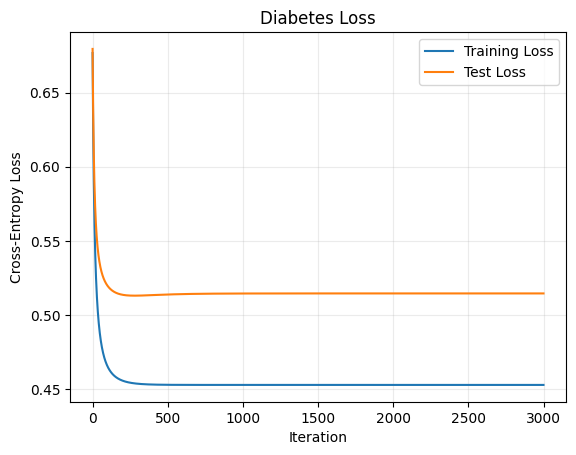

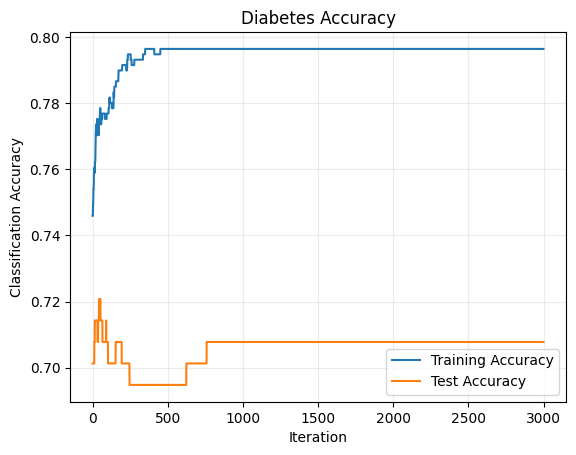

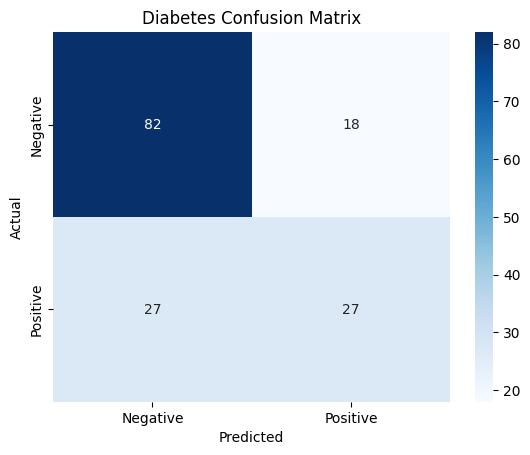

In [14]:
# TRAINING AND TEST LOSS, PROBLEM 1

plt.plot(train_loss_1, label="Training Loss")
plt.plot(test_loss_1, label="Test Loss")
plt.xlabel("Iteration")
plt.ylabel("Cross-Entropy Loss")
plt.title("Diabetes Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


# TRAINING AND TEST ACCURACY, PROBLEM 1

plt.plot(train_accuracy_1, label="Training Accuracy")
plt.plot(test_accuracy_1, label="Test Accuracy")
plt.xlabel("Iteration")
plt.ylabel("Classification Accuracy")
plt.title("Diabetes Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


# CONFUSION MATRIX, PROBLEM 1

sns.heatmap(
    confusion_1,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Diabetes Confusion Matrix")
plt.show()

In [15]:
# PROBLEM 2: LOAD THE CANCER DATASET

file_path = '/content/drive/My Drive/Courses/Intro-to-ML/Datasets/Cancer.csv'

Cancer = pd.DataFrame(pd.read_csv(file_path))
Cancer.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [16]:
# CHECK THE DATA

print(Cancer.isnull().sum() * 100 / Cancer.shape[0])

# Exclude the ID and the completely empty column.
# The remaining 30 columns are the input features.
X_cancer = Cancer.drop(
    columns=['id', 'diagnosis', 'Unnamed: 32']
)

# Malignant = 1; benign = 0.
Y_cancer = (Cancer['diagnosis'] == 'M').astype(int).to_numpy()

print("Number of input features:", X_cancer.shape[1])


# 80/20 TRAINING AND TEST SPLIT

X_train_df, X_test_df, Y_train_2, Y_test_2 = train_test_split(
    X_cancer,
    Y_cancer,
    test_size=0.20,
    random_state=42,
    stratify=Y_cancer
)

scaler_2 = StandardScaler()

X_train_2 = scaler_2.fit_transform(X_train_df)
X_test_2 = scaler_2.transform(X_test_df)

print("Training samples:", len(Y_train_2))
print("Test samples:", len(Y_test_2))

id                           0.0
diagnosis                    0.0
radius_mean                  0.0
texture_mean                 0.0
perimeter_mean               0.0
area_mean                    0.0
smoothness_mean              0.0
compactness_mean             0.0
concavity_mean               0.0
concave points_mean          0.0
symmetry_mean                0.0
fractal_dimension_mean       0.0
radius_se                    0.0
texture_se                   0.0
perimeter_se                 0.0
area_se                      0.0
smoothness_se                0.0
compactness_se               0.0
concavity_se                 0.0
concave points_se            0.0
symmetry_se                  0.0
fractal_dimension_se         0.0
radius_worst                 0.0
texture_worst                0.0
perimeter_worst              0.0
area_worst                   0.0
smoothness_worst             0.0
compactness_worst            0.0
concavity_worst              0.0
concave points_worst         0.0
symmetry_w

In [17]:
# PROBLEM 2.1: LOGISTIC REGRESSION USING ALL 30 FEATURES

learning_rate_2 = 0.1
max_iterations_2 = 3000

theta_2, train_loss_2, test_loss_2, \
train_accuracy_2, test_accuracy_2 = gradient_descent(
    X_train_2,
    Y_train_2,
    X_test_2,
    Y_test_2,
    learning_rate_2,
    max_iterations_2
)

results_2, confusion_2 = evaluate_model(
    theta_2, X_test_2, Y_test_2
)

print(pd.Series(results_2).round(4))
print("\nConfusion matrix:")
print(confusion_2)

Accuracy     0.9737
Precision    0.9756
Recall       0.9524
F1 Score     0.9639
dtype: float64

Confusion matrix:
[[71  1]
 [ 2 40]]


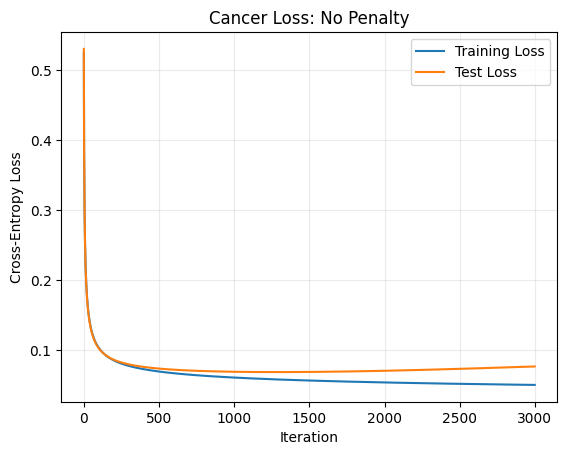

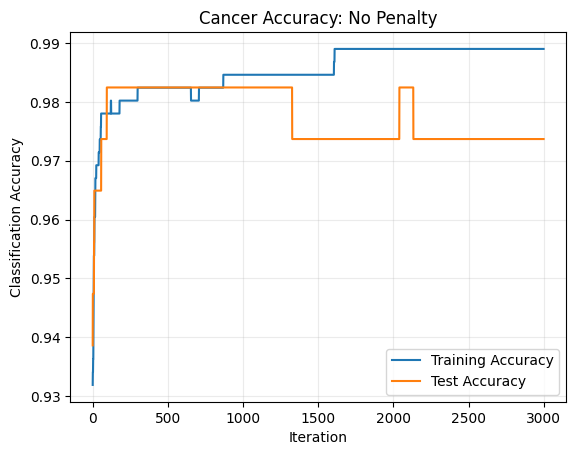

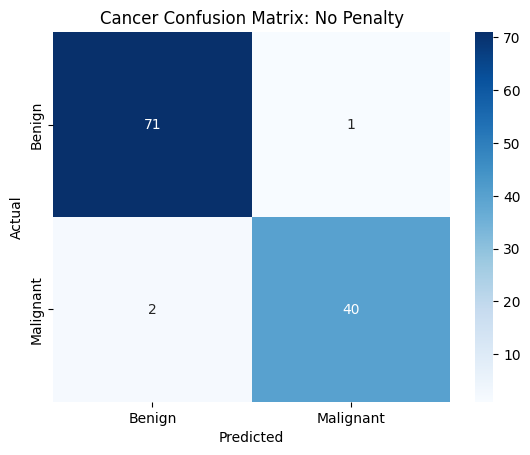

In [18]:
# TRAINING AND TEST LOSS, PROBLEM 2.1

plt.plot(train_loss_2, label="Training Loss")
plt.plot(test_loss_2, label="Test Loss")
plt.xlabel("Iteration")
plt.ylabel("Cross-Entropy Loss")
plt.title("Cancer Loss: No Penalty")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


# TRAINING AND TEST ACCURACY, PROBLEM 2.1

plt.plot(train_accuracy_2, label="Training Accuracy")
plt.plot(test_accuracy_2, label="Test Accuracy")
plt.xlabel("Iteration")
plt.ylabel("Classification Accuracy")
plt.title("Cancer Accuracy: No Penalty")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


# CONFUSION MATRIX, PROBLEM 2.1

sns.heatmap(
    confusion_2,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Cancer Confusion Matrix: No Penalty")
plt.show()

In [19]:
# PROBLEM 2.2: ADD A WEIGHT PENALTY

penalty_2 = 10

theta_2_l2, train_loss_2_l2, test_loss_2_l2, \
train_accuracy_2_l2, test_accuracy_2_l2 = gradient_descent(
    X_train_2,
    Y_train_2,
    X_test_2,
    Y_test_2,
    learning_rate_2,
    max_iterations_2,
    penalty=penalty_2
)

results_2_l2, confusion_2_l2 = evaluate_model(
    theta_2_l2, X_test_2, Y_test_2
)

print(pd.Series(results_2_l2).round(4))
print("\nConfusion matrix:")
print(confusion_2_l2)

Accuracy     0.9825
Precision    1.0000
Recall       0.9524
F1 Score     0.9756
dtype: float64

Confusion matrix:
[[72  0]
 [ 2 40]]


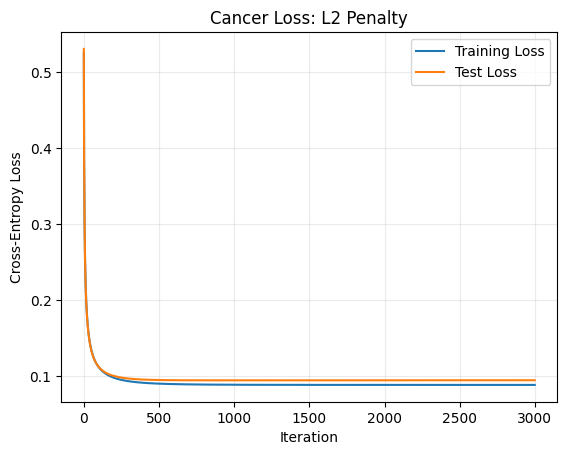

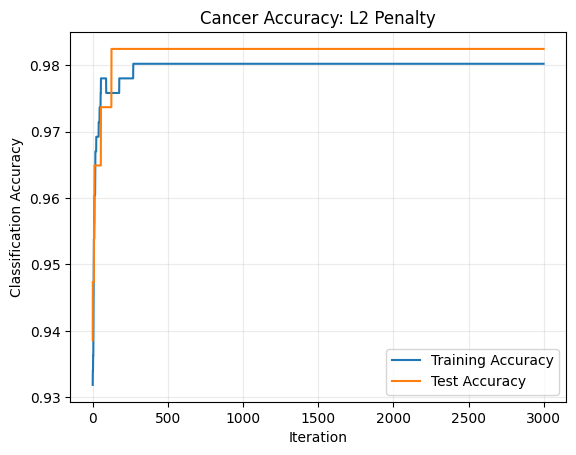

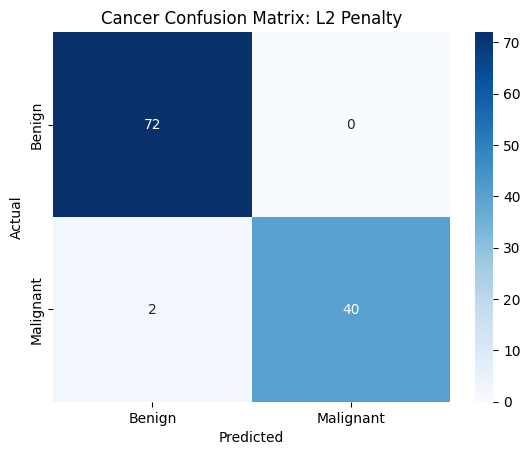

,Accuracy,Precision,Recall,F1 Score,Weight Norm
No Penalty,0.9737,0.9756,0.9524,0.9639,4.3109
L2 Penalty,0.9825,1.0000,0.9524,0.9756,1.8233


In [20]:
# TRAINING AND TEST LOSS, PROBLEM 2.2

plt.plot(train_loss_2_l2, label="Training Loss")
plt.plot(test_loss_2_l2, label="Test Loss")
plt.xlabel("Iteration")
plt.ylabel("Cross-Entropy Loss")
plt.title("Cancer Loss: L2 Penalty")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


# TRAINING AND TEST ACCURACY, PROBLEM 2.2

plt.plot(train_accuracy_2_l2, label="Training Accuracy")
plt.plot(test_accuracy_2_l2, label="Test Accuracy")
plt.xlabel("Iteration")
plt.ylabel("Classification Accuracy")
plt.title("Cancer Accuracy: L2 Penalty")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


# CONFUSION MATRIX, PROBLEM 2.2

sns.heatmap(
    confusion_2_l2,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Cancer Confusion Matrix: L2 Penalty")
plt.show()


# FINAL COMPARISON

comparison = pd.DataFrame(
    [results_2, results_2_l2],
    index=['No Penalty', 'L2 Penalty']
)

comparison['Weight Norm'] = [
    np.linalg.norm(theta_2[1:]),
    np.linalg.norm(theta_2_l2[1:])
]

comparison.round(4)